In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# EDA

In [2]:
df = pd.read_csv("D:\\Data science\\Assignments\\Answers\\PCA\\wine.csv")
df

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


array([[<Axes: title={'center': 'Type'}>,
        <Axes: title={'center': 'Alcohol'}>,
        <Axes: title={'center': 'Malic'}>,
        <Axes: title={'center': 'Ash'}>],
       [<Axes: title={'center': 'Alcalinity'}>,
        <Axes: title={'center': 'Magnesium'}>,
        <Axes: title={'center': 'Phenols'}>,
        <Axes: title={'center': 'Flavanoids'}>],
       [<Axes: title={'center': 'Nonflavanoids'}>,
        <Axes: title={'center': 'Proanthocyanins'}>,
        <Axes: title={'center': 'Color'}>,
        <Axes: title={'center': 'Hue'}>],
       [<Axes: title={'center': 'Dilution'}>,
        <Axes: title={'center': 'Proline'}>, <Axes: >, <Axes: >]],
      dtype=object)

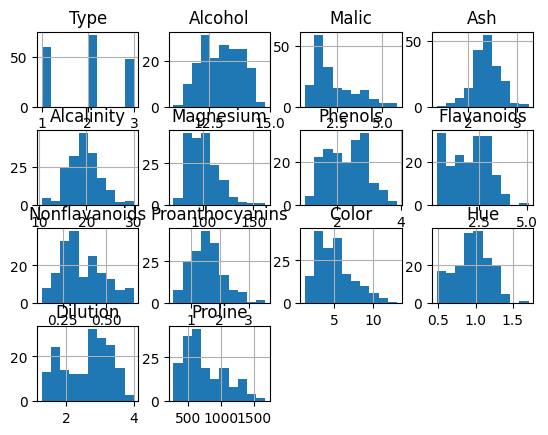

In [3]:
df.hist()

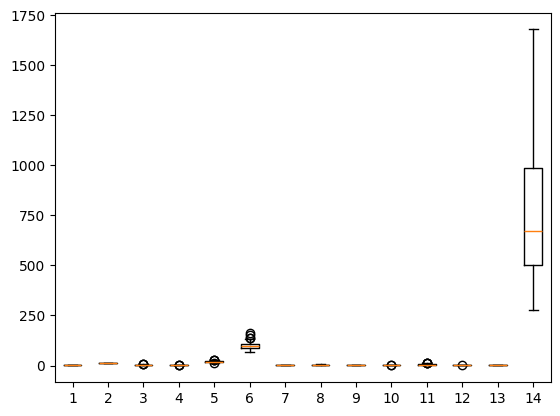

In [4]:
plt.boxplot(df)
plt.show()

In [5]:
df.corr()

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
Type,1.000000,-0.328222,0.437776,-0.049643,0.517859,-0.209179,-0.719163,-0.847498,0.489109,-0.499130,0.265668,-0.617369,-0.788230,-0.633717
Alcohol,-0.328222,1.000000,0.094397,0.211545,-0.310235,0.270798,0.289101,0.236815,-0.155929,0.136698,0.546364,-0.071747,0.072343,0.643720
Malic,0.437776,0.094397,1.000000,0.164045,0.288500,-0.054575,-0.335167,-0.411007,0.292977,-0.220746,0.248985,-0.561296,-0.368710,-0.192011
Ash,-0.049643,0.211545,0.164045,1.000000,0.443367,0.286587,0.128980,0.115077,0.186230,0.009652,0.258887,-0.074667,0.003911,0.223626
Alcalinity,0.517859,-0.310235,0.288500,0.443367,1.000000,-0.083333,-0.321113,-0.351370,0.361922,-0.197327,0.018732,-0.273955,-0.276769,-0.440597
Magnesium,-0.209179,0.270798,-0.054575,0.286587,-0.083333,1.000000,0.214401,0.195784,-0.256294,0.236441,0.199950,0.055398,0.066004,0.393351
Phenols,-0.719163,0.289101,-0.335167,0.128980,-0.321113,0.214401,1.000000,0.864564,-0.449935,0.612413,-0.055136,0.433681,0.699949,0.498115
Flavanoids,-0.847498,0.236815,-0.411007,0.115077,-0.351370,0.195784,0.864564,1.000000,-0.537900,0.652692,-0.172379,0.543479,0.787194,0.494193
Nonflavanoids,0.489109,-0.155929,0.292977,0.186230,0.361922,-0.256294,-0.449935,-0.537900,1.000000,-0.365845,0.139057,-0.262640,-0.503270,-0.311385
Proanthocyanins,-0.499130,0.136698,-0.220746,0.009652,-0.197327,0.236441,0.612413,0.652692,-0.365845,1.000000,-0.025250,0.295544,0.519067,0.330417


# apply standerdization and PCA

In [8]:
X= df.iloc[:,1:]
Y= df['Type']

In [9]:
SS = StandardScaler()
SS_X = SS.fit_transform(X)
SS_X = pd.DataFrame(SS_X)
SS_X.columns = X.columns
SS_X

,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,0.876275,2.974543,0.305159,0.301803,-0.332922,-0.985614,-1.424900,1.274310,-0.930179,1.142811,-1.392758,-1.231206,-0.021952
174,0.493343,1.412609,0.414820,1.052516,0.158572,-0.793334,-1.284344,0.549108,-0.316950,0.969783,-1.129518,-1.485445,0.009893
175,0.332758,1.744744,-0.389355,0.151661,1.422412,-1.129824,-1.344582,0.549108,-0.422075,2.224236,-1.612125,-1.485445,0.280575
176,0.209232,0.227694,0.012732,0.151661,1.422412,-1.033684,-1.354622,1.354888,-0.229346,1.834923,-1.568252,-1.400699,0.296498


In [10]:
pca = PCA()
pc = pca.fit_transform(SS_X)
pc = pd.DataFrame(SS_X)

pc

,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,0.876275,2.974543,0.305159,0.301803,-0.332922,-0.985614,-1.424900,1.274310,-0.930179,1.142811,-1.392758,-1.231206,-0.021952
174,0.493343,1.412609,0.414820,1.052516,0.158572,-0.793334,-1.284344,0.549108,-0.316950,0.969783,-1.129518,-1.485445,0.009893
175,0.332758,1.744744,-0.389355,0.151661,1.422412,-1.129824,-1.344582,0.549108,-0.422075,2.224236,-1.612125,-1.485445,0.280575
176,0.209232,0.227694,0.012732,0.151661,1.422412,-1.033684,-1.354622,1.354888,-0.229346,1.834923,-1.568252,-1.400699,0.296498


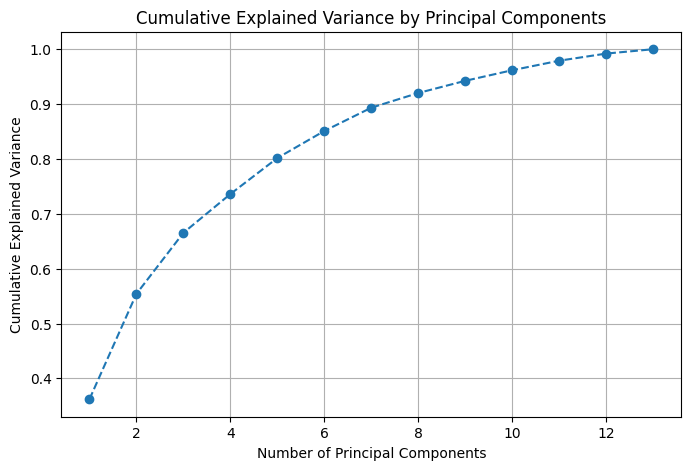

,Answer
0,10


In [13]:
# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
# Create a scree plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.title('Cumulative Explained Variance by Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid()
plt.show()
# Determine optimal number of components (e.g., 95% explained variance)
optimal_components = np.argmax(cumulative_variance >= 0.95) + 1
# Assign result back to SS_X
optimal_components = pd.DataFrame({'Answer': [optimal_components]})
optimal_components

In [14]:
pc = pc.drop(['Ash', 'Magnesium', 'Color'], axis=1)
pc

,Alcohol,Malic,Alcalinity,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Hue,Dilution,Proline
0,1.518613,-0.562250,-1.169593,0.808997,1.034819,-0.659563,1.224884,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-2.490847,0.568648,0.733629,-0.820719,-0.544721,0.406051,1.113449,0.965242
2,0.196879,0.021231,-0.268738,0.808997,1.215533,-0.498407,2.135968,0.318304,0.788587,1.395148
3,1.691550,-0.346811,-0.809251,2.491446,1.466525,-0.981875,1.032155,-0.427544,1.184071,2.334574
4,0.295700,0.227694,0.451946,0.808997,0.663351,0.226796,0.401404,0.362177,0.449601,-0.037874
...,...,...,...,...,...,...,...,...,...,...
173,0.876275,2.974543,0.301803,-0.985614,-1.424900,1.274310,-0.930179,-1.392758,-1.231206,-0.021952
174,0.493343,1.412609,1.052516,-0.793334,-1.284344,0.549108,-0.316950,-1.129518,-1.485445,0.009893
175,0.332758,1.744744,0.151661,-1.129824,-1.344582,0.549108,-0.422075,-1.612125,-1.485445,0.280575
176,0.209232,0.227694,0.151661,-1.033684,-1.354622,1.354888,-0.229346,-1.568252,-1.400699,0.296498


In [15]:
df_pc = pd.concat([Y,pc], axis=1)
df_pc

,Type,Alcohol,Malic,Alcalinity,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Hue,Dilution,Proline
0,1,1.518613,-0.562250,-1.169593,0.808997,1.034819,-0.659563,1.224884,0.362177,1.847920,1.013009
1,1,0.246290,-0.499413,-2.490847,0.568648,0.733629,-0.820719,-0.544721,0.406051,1.113449,0.965242
2,1,0.196879,0.021231,-0.268738,0.808997,1.215533,-0.498407,2.135968,0.318304,0.788587,1.395148
3,1,1.691550,-0.346811,-0.809251,2.491446,1.466525,-0.981875,1.032155,-0.427544,1.184071,2.334574
4,1,0.295700,0.227694,0.451946,0.808997,0.663351,0.226796,0.401404,0.362177,0.449601,-0.037874
...,...,...,...,...,...,...,...,...,...,...,...
173,3,0.876275,2.974543,0.301803,-0.985614,-1.424900,1.274310,-0.930179,-1.392758,-1.231206,-0.021952
174,3,0.493343,1.412609,1.052516,-0.793334,-1.284344,0.549108,-0.316950,-1.129518,-1.485445,0.009893
175,3,0.332758,1.744744,0.151661,-1.129824,-1.344582,0.549108,-0.422075,-1.612125,-1.485445,0.280575
176,3,0.209232,0.227694,0.151661,-1.033684,-1.354622,1.354888,-0.229346,-1.568252,-1.400699,0.296498


# clustring to original data

In [70]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
model = KMeans(n_clusters = 2)
df["Kmeans"] = model.fit_predict(X)

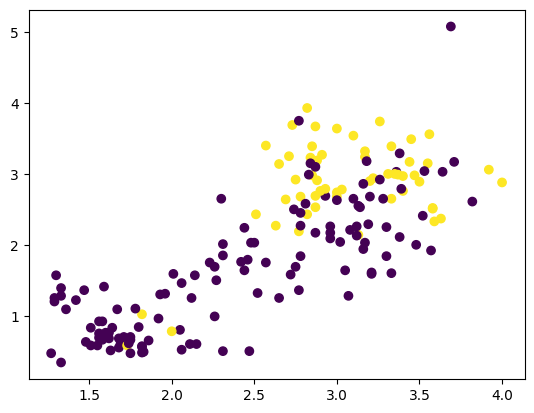

In [71]:
plt.scatter(df['Dilution'],df['Flavanoids'], c=df["Kmeans"])
plt.show()

In [79]:
score = silhouette_score(X, df["Kmeans"])
print("Kmeans - score:",np.round(score,2))

Kmeans - score: 0.52


In [80]:
scores = []
for i in range(2,11):
    model = KMeans(n_clusters=i)
    df["Kmeans"] = model.fit_predict(X)
    scores.append(silhouette_score(X, df["Kmeans"]))
    

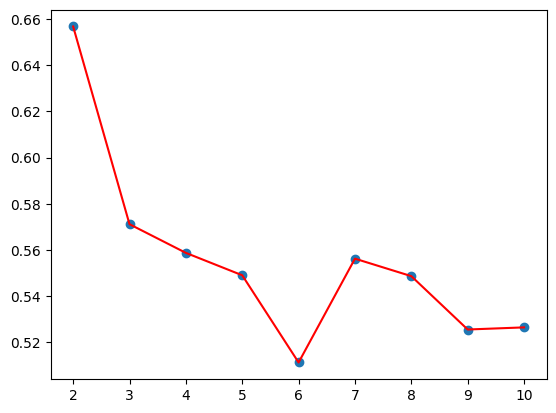

In [81]:
plt.scatter(range(2,11), scores)
plt.plot(range(2,11), scores, color='red')
plt.show()

# Clustring to pca data set

In [82]:
model = KMeans(n_clusters = 2)
df_pc["Kmeans"] = model.fit_predict(pc)

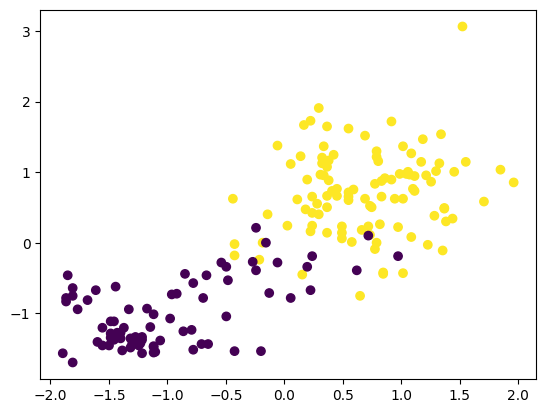

In [83]:
plt.scatter(df_pc['Dilution'],df_pc['Flavanoids'], c=df_pc["Kmeans"])
plt.show()

In [84]:
score = silhouette_score(pc, df_pc["Kmeans"])
print("Kmeans - score:",np.round(score,2))

Kmeans - score: 0.31


In [89]:
scores = []
for i in range(2,11):
    model = KMeans(n_clusters=i)
    df_pc["Kmeans"] = model.fit_predict(pc)
    scores.append(silhouette_score(pc, df_pc["Kmeans"]))
    

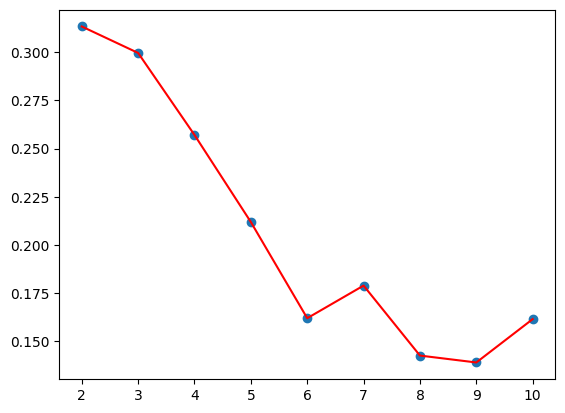

In [90]:
plt.scatter(range(2,11), scores)
plt.plot(range(2,11), scores, color='red')
plt.show()

Comparison of Clustering Results (Original vs. PCA-Transformed Data):

1. Silhouette Score Comparison:
Silhouette Score on Original Scaled Data: 0.52  
Silhouette Score on PCA-Transformed Data: 0.31  
The silhouette scores are variying. This suggests that PCA had little impact on the overall quality of clustering as measured by silhouette score.

2. Visual Analysis of Scatter Plots:
The first scatter plot shows clustering results on original scaled data projected onto the first two principal components.  
The second scatter plot shows clustering results on PCA-transformed data (which is already in the space of principal components).


3. Impact of Dimensionality Reduction using PCA on Clustering:
PCA reduced the dimensionality from 13 to 10 (or effectively to the number of components retained, though here we used all for clustering PCA data).
Based on the silhouette scores and visual resemblance of the cluster assignments in the 2D PCA space, it appears that reducing dimensionality using PCA (and specifically, considering the first few components which capture significant variance) did significantly worsen the clustering results for this dataset.  

4. Potential Trade-offs of Using PCA for Clustering:
a) Computational Efficiency: Clustering on a reduced number of principal components is generally faster and requires less memory than clustering on the full dataset, especially for datasets with many features. This is a significant benefit for large datasets.  
b) Loss of Information: PCA is a dimensionality reduction technique and can result in some loss of information, particularly if not enough components are retained. While the first few components capture the most variance, some information is contained in the later components. However, for this dataset, the clustering results suggest that the lost information did drastically affect the ability to find meaningful clusters.  
c) Interpretability: The principal components are linear combinations of the original features, which makes interpreting the meaning of the clusters in terms of the original features more challenging compared to clustering directly on the original features.  
d) Noise Reduction: PCA can sometimes help in clustering by reducing noise in the data, as the principal components focus on the dimensions with the highest variance.  

5. Summary of Key Findings:
- The silhouette scores for clustering on original scaled data and PCA-transformed data are very different, indicating that PCA did not preserved the cluster structure effectively for this dataset.
- Visual inspection of the scatter plots in the first two principal components space shows different cluster separation, further supporting that PCA did negatively impact the clustering.

## Summary:

### Data Analysis Key Findings

*   Applying KMeans clustering with 3 clusters to the scaled original data yielded a silhouette score of 0.52.
*   Applying KMeans clustering with 3 clusters to the PCA-transformed data also yielded a silhouette score of 0.31.
*   Visualizations in the space of the first two principal components showed a largely similar pattern of cluster assignments when clustering was performed on either the original scaled data or the PCA-transformed data.
*   The first two principal components combined explain over 55% of the variance in the dataset.

### Insights or Next Steps

*   The silhouette scores suggest that for this dataset, PCA did not significantly improve the clustering performance, indicating that the intrinsic cluster structure was preserved in the PCA space.
*   Future work could involve exploring the optimal number of principal components to retain for clustering by evaluating performance with varying numbers of components or analyzing the loadings of the principal components to understand feature contributions.
